In [1]:
import os
from pathlib import Path

import pandas as pd

# Jupyter normally runs here or in the repository root.
root = next((folder for folder in (Path.cwd(), Path.cwd().parent)
             if (folder / "data" / "split.csv").is_file()), None)
if root is None:
    raise FileNotFoundError("Start the notebook from 04_XGBoost or the repository root.")
output = root / "results" / "xgboost"
figures = output / "figures"
figures.mkdir(parents=True, exist_ok=True)

data = pd.read_csv(os.environ.get("TELCO_CLEAN_DATA", root / "data" / "telco_clean.csv"))
split = pd.read_csv(root / "data" / "split.csv")

assert split["row_id"].tolist() == list(data.index)

train_rows = split.loc[split["subset"] == "train"]
test_rows = split.loc[split["subset"] == "test"]
train_ids = train_rows["row_id"]
test_ids = test_rows["row_id"]
assert set(split["subset"]) == {"train", "test"}
assert set(train_rows["cv_fold"]) == set(range(1, 11))
assert test_rows["cv_fold"].eq(-1).all()

In [2]:
category_levels = {
    "Internet Service": ["DSL", "Fiber optic", "No"],
    "Contract": ["Month-to-month", "One year", "Two year"],
    "Payment Method": ["Bank transfer (automatic)", "Credit card (automatic)",
                       "Electronic check", "Mailed check"],
}

categories = data[list(category_levels)].copy()
for column, levels in category_levels.items():
    categories[column] = pd.Categorical(categories[column], categories=levels)
assert categories.notna().all().all()

dummy_columns = pd.get_dummies(categories, drop_first=True, dtype=int)
continuous = ["Tenure Months", "Monthly Charges", "Total Charges"]
binary = data.drop(columns=continuous + list(category_levels) + ["Churn", "ServiceCount"])
X = pd.concat([data[continuous], dummy_columns, binary], axis=1)
y = data["Churn"]

X_train, y_train = X.loc[train_ids], y.loc[train_ids]
X_test, y_test = X.loc[test_ids], y.loc[test_ids]
print(X_train.shape, X_test.shape)

(5634, 23) (1409, 23)


In [3]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=3,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    tree_method="hist",
    random_state=42,
    n_jobs=1,
)
xgb_model.fit(X_train, y_train)
print("Initial model training complete.")

Initial model training complete.


In [4]:
from sklearn.model_selection import PredefinedSplit, RandomizedSearchCV

cv = PredefinedSplit(train_rows["cv_fold"].to_numpy() - 1)
assert cv.get_n_splits() == 10

param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [2, 3, 4, 5, 6],
    "learning_rate": [0.01, 0.05, 0.1],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.8, 1.0],
    "min_child_weight": [1, 3, 5],
}

random_search = RandomizedSearchCV(
    XGBClassifier(tree_method="hist", eval_metric="logloss", random_state=42, n_jobs=1),
    param_distributions=param_grid,
    n_iter=20, scoring="roc_auc", cv=cv,
    random_state=42, n_jobs=-1, verbose=1,
)
random_search.fit(X_train, y_train)
xgb_tuned = random_search.best_estimator_
print("Selected parameters:", random_search.best_params_)
print(f"Mean 10-fold validation AUC: {random_search.best_score_:.4f}")

Fitting 10 folds for each of 20 candidates, totalling 200 fits


Selected parameters: {'subsample': 1.0, 'n_estimators': 200, 'min_child_weight': 3, 'max_depth': 3, 'learning_rate': 0.05, 'colsample_bytree': 0.8}
Mean 10-fold validation AUC: 0.8652


In [5]:
import numpy as np
from sklearn.metrics import f1_score
from sklearn.model_selection import cross_val_predict

oof_prob = cross_val_predict(
    xgb_tuned, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1
)[:, 1]
thresholds = np.arange(0.05, 0.96, 0.01)
f1_scores = [
    f1_score(y_train, (oof_prob >= threshold).astype(int))
    for threshold in thresholds
]
best_threshold = thresholds[np.argmax(f1_scores)]

print(f"Threshold selected on the training set: {best_threshold:.2f}")
print(f"Training out-of-fold F1 at the selected threshold: {max(f1_scores):.4f}")

Threshold selected on the training set: 0.36
Training out-of-fold F1 at the selected threshold: 0.6546


In [6]:
from sklearn.metrics import (
    accuracy_score, confusion_matrix, precision_score, recall_score, roc_auc_score,
)

assert X_test.index.equals(y_test.index)
y_prob = xgb_model.predict_proba(X_test)[:, 1]
y_pred = xgb_model.predict(X_test)
tuned_prob = xgb_tuned.predict_proba(X_test)[:, 1]
tuned_pred = xgb_tuned.predict(X_test)
threshold_pred = (tuned_prob >= best_threshold).astype(int)

def evaluate_model(y_true, prediction, probability):
    tn, fp, fn, tp = confusion_matrix(y_true, prediction, labels=[0, 1]).ravel()
    return {
        "Accuracy": accuracy_score(y_true, prediction),
        "Precision": precision_score(y_true, prediction, zero_division=0),
        "Recall": recall_score(y_true, prediction, zero_division=0),
        "F1-score": f1_score(y_true, prediction, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, probability),
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
    }

selected_label = f"Tuned (OOF {best_threshold:.2f})"
metrics_df = pd.DataFrame({
    "Initial (0.50)": evaluate_model(y_test, y_pred, y_prob),
    "Tuned (0.50)": evaluate_model(y_test, tuned_pred, tuned_prob),
    selected_label: evaluate_model(y_test, threshold_pred, tuned_prob),
}).T
metrics_df.index.name = "experiment"
metrics_df["threshold"] = [0.5, 0.5, best_threshold]
metrics_df["n_features"] = X_train.shape[1]
metrics_df.to_csv(output / "xgboost_test_metrics.csv")
display(metrics_df.round(4))

,Accuracy,Precision,Recall,F1-score,ROC-AUC,TN,FP,FN,TP,threshold,n_features
experiment,,,,,,,,,,,
Initial (0.50),0.8070,0.6635,0.5535,0.6035,0.8530,930.0,105.0,167.0,207.0,0.50,23
Tuned (0.50),0.8027,0.6548,0.5428,0.5936,0.8554,928.0,107.0,171.0,203.0,0.50,23
Tuned (OOF 0.36),0.7764,0.5613,0.7219,0.6316,0.8554,824.0,211.0,104.0,270.0,0.36,23


In [7]:
test_predictions = pd.DataFrame({
    "row_id": X_test.index.to_numpy(),
    "Churn": y_test.to_numpy(),
    "xgb_initial_score": y_prob,
    "xgb_initial_pred_0.5": y_pred,
    "xgb_tuned_score": tuned_prob,
    "xgb_tuned_pred_0.5": tuned_pred,
    "xgb_tuned_pred_oof_threshold": threshold_pred,
    "xgb_oof_threshold": float(best_threshold),
})
test_predictions.to_csv(output / "xgboost_test_predictions.csv", index=False)
display(test_predictions.sample(5, random_state=42).round(4))

,row_id,Churn,xgb_initial_score,xgb_initial_pred_0.5,xgb_tuned_score,xgb_tuned_pred_0.5,xgb_tuned_pred_oof_threshold,xgb_oof_threshold
353,1774,1,0.5612,1,0.5835,1,1,0.36
864,4468,0,0.0070,0,0.0082,0,0,0.36
1310,6555,0,0.2003,0,0.2113,0,0,0.36
192,926,1,0.4076,0,0.4598,0,1,0.36
782,4025,0,0.0922,0,0.0854,0,0,0.36


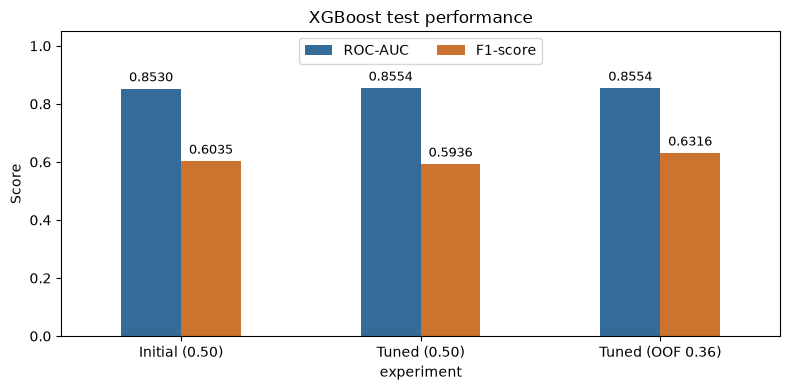

In [8]:
import matplotlib.pyplot as plt

ax = metrics_df[["ROC-AUC", "F1-score"]].plot.bar(
    figsize=(8, 4), rot=0, color=["#356B99", "#CC732F"]
)
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.4f", padding=3, fontsize=9)
ax.set(title="XGBoost test performance", ylabel="Score", ylim=(0, 1.05))
ax.legend(loc="upper center", ncol=2)
plt.tight_layout()
plt.savefig(figures / "test_performance.png", dpi=150, bbox_inches="tight")
plt.show()

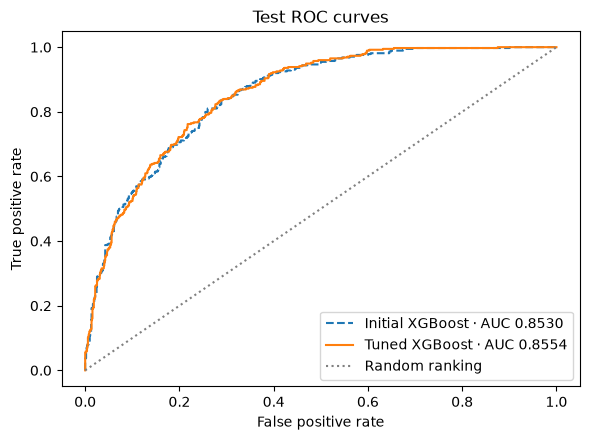

In [9]:
from sklearn.metrics import roc_curve

fig, ax = plt.subplots(figsize=(6, 4.5))
for name, score, auc, style in [
    ("Initial XGBoost", y_prob, metrics_df.loc["Initial (0.50)", "ROC-AUC"], "--"),
    ("Tuned XGBoost", tuned_prob, metrics_df.loc["Tuned (0.50)", "ROC-AUC"], "-"),
]:
    fpr, tpr, _ = roc_curve(y_test, score)
    ax.plot(fpr, tpr, style, label=f"{name} · AUC {auc:.4f}")
ax.plot([0, 1], [0, 1], ":", color="gray", label="Random ranking")
ax.set(title="Test ROC curves", xlabel="False positive rate", ylabel="True positive rate")
ax.legend(loc="lower right")
fig.tight_layout()
plt.savefig(figures / "roc.png", dpi=150, bbox_inches="tight")
plt.show()

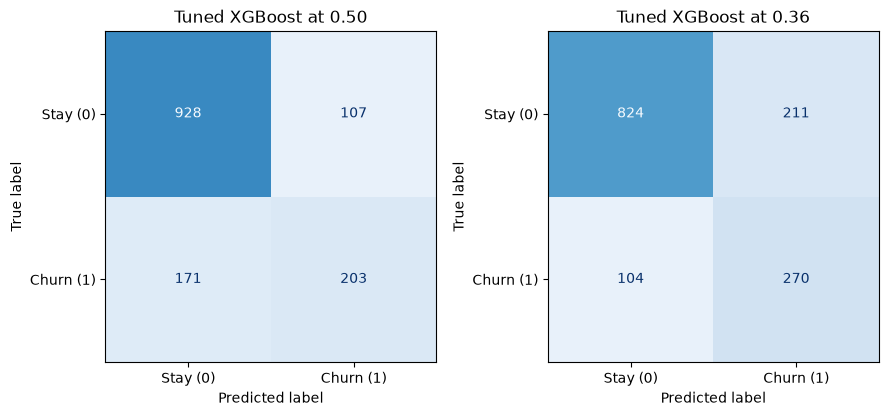

In [10]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(9, 4.2))
for ax, prediction, cutoff in [
    (axes[0], tuned_pred, 0.50),
    (axes[1], threshold_pred, best_threshold),
]:
    ConfusionMatrixDisplay.from_predictions(
        y_test, prediction, labels=[0, 1], display_labels=["Stay (0)", "Churn (1)"],
        ax=ax, cmap="Blues", colorbar=False, values_format="d",
        im_kw={"vmin": 0, "vmax": len(y_test)},
    )
    ax.set_title(f"Tuned XGBoost at {cutoff:.2f}")
fig.tight_layout()
plt.savefig(figures / "confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()

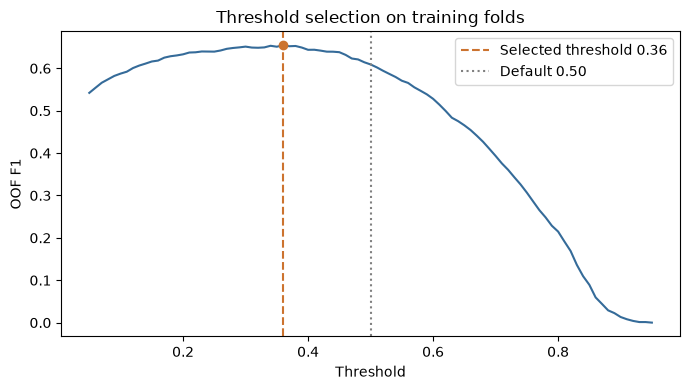

In [11]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(thresholds, f1_scores, color="#356B99")
ax.axvline(best_threshold, color="#CC732F", linestyle="--",
           label=f"Selected threshold {best_threshold:.2f}")
ax.axvline(0.50, color="gray", linestyle=":", label="Default 0.50")
ax.scatter(best_threshold, max(f1_scores), color="#CC732F", zorder=3)
ax.set(title="Threshold selection on training folds", xlabel="Threshold", ylabel="OOF F1")
ax.legend()
fig.tight_layout()
plt.savefig(figures / "threshold.png", dpi=150, bbox_inches="tight")
plt.show()

,Mean AUC decrease
Tenure Months,0.0648
Contract,0.0511
Dependents,0.0357
Internet Service,0.0352
Total Charges,0.0049
Payment Method,0.0032
Online Security,0.0030
Monthly Charges,0.0026
Partner,0.0023
Paperless Billing,0.0022


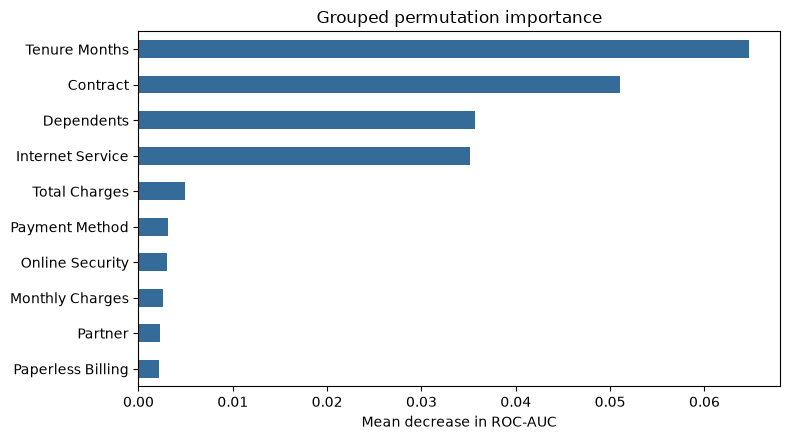

In [12]:
def to_original(name):
    for field in category_levels:
        if name.startswith(field + "_"):
            return field
    return name

feature_groups = {}
for column in X_test.columns:
    feature = to_original(column)
    feature_groups.setdefault(feature, []).append(column)

rng = np.random.default_rng(42)
tuned_auc = metrics_df.loc["Tuned (0.50)", "ROC-AUC"]
permutation_scores = {}
for feature, columns in feature_groups.items():
    auc_drops = []
    for _ in range(20):
        shuffled = X_test.copy()
        order = rng.permutation(len(X_test))
        shuffled.loc[:, columns] = X_test[columns].to_numpy()[order]
        shuffled_prob = xgb_tuned.predict_proba(shuffled)[:, 1]
        auc_drops.append(tuned_auc - roc_auc_score(y_test, shuffled_prob))
    permutation_scores[feature] = np.mean(auc_drops)

importance = pd.Series(permutation_scores, name="Mean AUC decrease")
importance = importance.sort_values(ascending=False)
display(importance.round(4).to_frame())
ax = importance.head(10).sort_values().plot.barh(figsize=(8, 4.5), color="#356B99")
ax.axvline(0, color="gray", linestyle=":")
ax.set(title="Grouped permutation importance", xlabel="Mean decrease in ROC-AUC")
plt.tight_layout()
plt.savefig(figures / "permutation_importance.png", dpi=150, bbox_inches="tight")
plt.show()

In [13]:
initial_importance = pd.Series(xgb_model.feature_importances_, index=X_train.columns)
initial_importance = initial_importance.groupby(to_original).sum().sort_values(ascending=False)
display(initial_importance.round(4).to_frame(name="Initial model importance"))

,Initial model importance
Internet Service,0.3279
Contract,0.2537
Payment Method,0.0936
Dependents,0.0751
Tenure Months,0.0404
Paperless Billing,0.0298
Online Security,0.0277
Streaming Movies,0.0255
Streaming TV,0.0191
Tech Support,0.0168


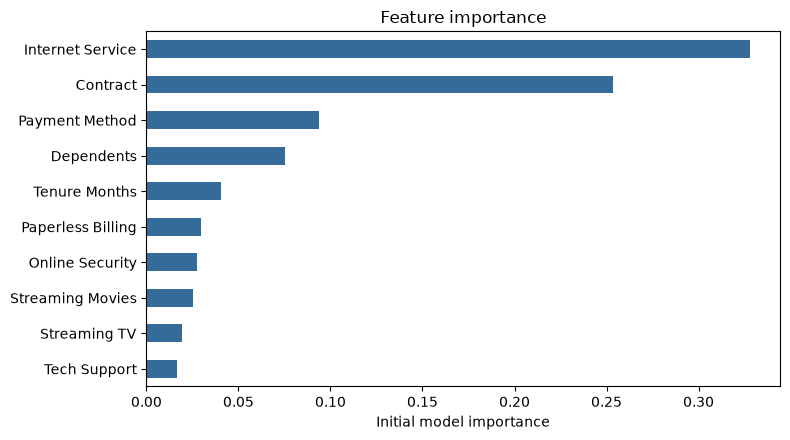

In [14]:
ax = initial_importance.head(10).sort_values().plot.barh(figsize=(8, 4.5), color="#356B99")
ax.axvline(0, color="gray", linestyle=":")
ax.set(title="Feature importance", xlabel="Initial model importance")
plt.tight_layout()
plt.savefig(figures / "initial_importance.png", dpi=150, bbox_inches="tight")
plt.show()

In [15]:
import shap
explainer =shap.TreeExplainer(xgb_tuned)

/workspace/.telco-env/venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [16]:
shap_values = explainer.shap_values(X)
print(shap_values.shape)

(7043, 23)


In [17]:
y_base = explainer.expected_value
print(y_base)

-1.0328947


In [18]:
data['pred'] = xgb_tuned.predict(X)
print(data['pred'].mean())

0.21553315348573052


In [19]:
j = 77

customer_explainer = pd.DataFrame({
    'feature': X.columns,
    'feature_value': X.iloc[j].values,
    'shap_value': shap_values[j] if not isinstance(shap_values, list) else shap_values[1][j]
})

customer_explainer = customer_explainer.reindex(
    customer_explainer.shap_value.abs().sort_values(ascending=False).index
)

display(customer_explainer)

,feature,feature_value,shap_value
0,Tenure Months,4.00,0.620941
3,Internet Service_Fiber optic,1.00,0.360790
6,Contract_Two year,0.00,0.252487
8,Payment Method_Electronic check,1.00,0.189738
15,Multiple Lines,1.00,0.177489
13,Dependents,0.00,0.166960
5,Contract_One year,0.00,0.135433
1,Monthly Charges,95.45,0.133006
22,Paperless Billing,1.00,0.127346
4,Internet Service_No,0.00,0.095272


In [20]:
from scipy.special import expit

# TreeExplainer explains the raw margin for this binary logistic objective.
shap_margin = y_base + shap_values.sum(axis=1)
model_margin = xgb_tuned.predict(X, output_margin=True)
model_probability = xgb_tuned.predict_proba(X)[:, 1]
np.testing.assert_allclose(shap_margin, model_margin, rtol=1e-5, atol=1e-5)
np.testing.assert_allclose(expit(shap_margin), model_probability, rtol=1e-5, atol=1e-6)
print(f"SHAP margin: {shap_margin[j]:.6f}, model margin: {model_margin[j]:.6f}")
print(f"SHAP probability: {expit(shap_margin[j]):.6f}, model probability: {model_probability[j]:.6f}")
print(f"Predicted class at the default threshold: {data['pred'].iloc[j]}")

SHAP margin: 1.538585, model margin: 1.538586
SHAP probability: 0.823259, model probability: 0.823259
Predicted class at the default threshold: 1


In [21]:
shap.initjs()
shap.force_plot(explainer.expected_value, shap_values[j], X.iloc[j])

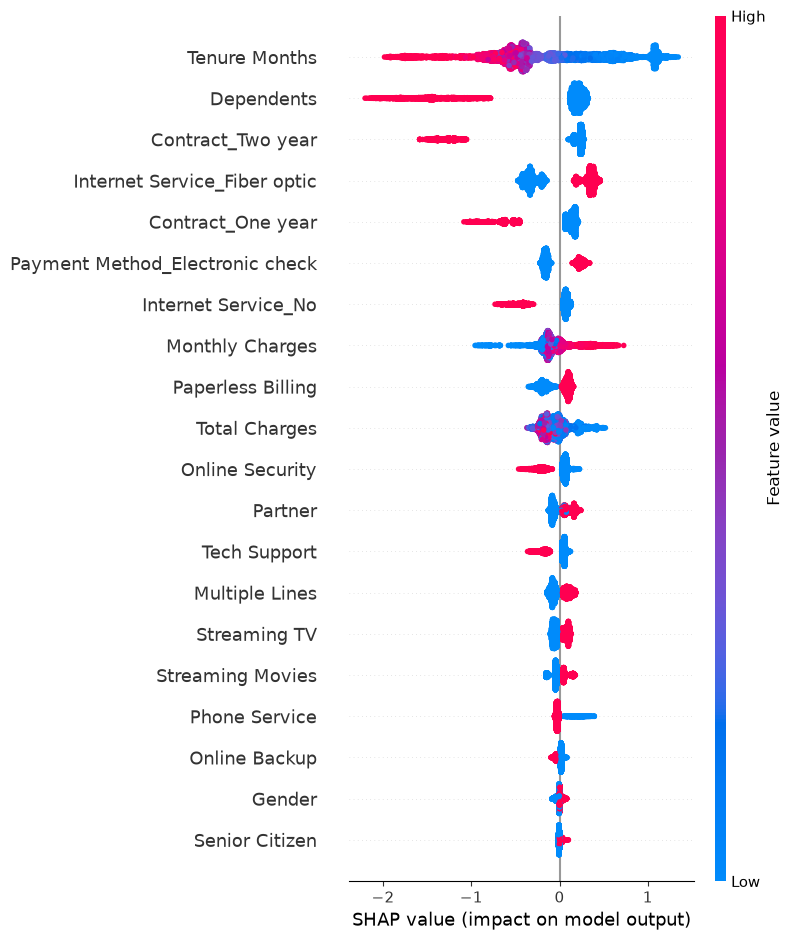

In [22]:
shap.summary_plot(shap_values, X)

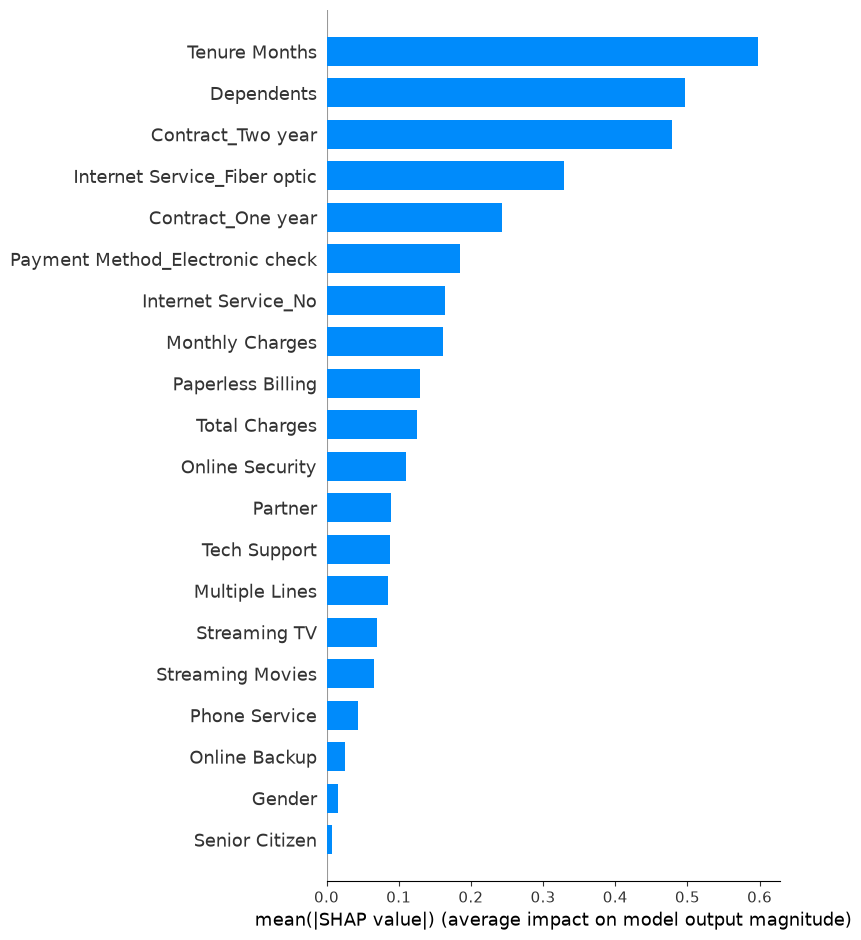

In [23]:
shap.summary_plot(shap_values, X, plot_type='bar')

In [24]:
shap_interaction_values = shap.TreeExplainer(xgb_tuned).shap_interaction_values(X)

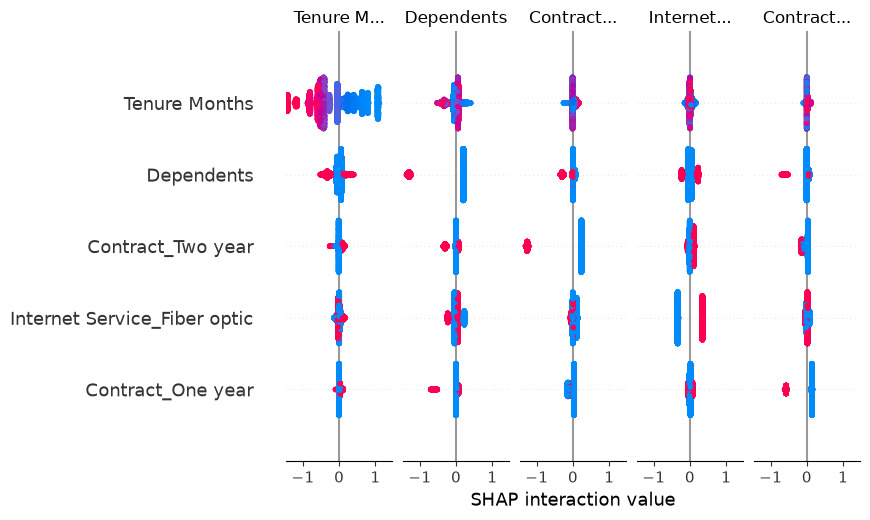

In [25]:
shap.summary_plot(shap_interaction_values, X, max_display=5)

In [26]:
# Refit with the same training-only search after removing Total Charges.
from sklearn.base import clone

X_train_reduced = X_train.drop(columns="Total Charges")
X_test_reduced = X_test.drop(columns="Total Charges")
reduced_search = clone(random_search).fit(X_train_reduced, y_train)
reduced_model = reduced_search.best_estimator_
reduced_oof = cross_val_predict(
    reduced_model, X_train_reduced, y_train, cv=cv, method="predict_proba", n_jobs=-1
)[:, 1]
reduced_test_score = reduced_model.predict_proba(X_test_reduced)[:, 1]

study_scores = []
study_features = []
for setting, columns, train_score, test_score in (
    ("full", X_train.columns, oof_prob, tuned_prob),
    ("reduced", X_train_reduced.columns, reduced_oof, reduced_test_score),
):
    design = split.assign(feature_set=setting, Churn=y, score=np.nan)
    design.loc[train_ids, "score"] = train_score.astype(np.float64)
    design.loc[test_ids, "score"] = test_score.astype(np.float64)
    study_scores.append(design)
    study_features.append(pd.DataFrame({"feature_set": setting, "feature": columns}))

pd.concat(study_scores, ignore_index=True).to_csv(output / "study_scores.csv", index=False)
pd.concat(study_features, ignore_index=True).to_csv(output / "study_features.csv", index=False)
print("Reduced XGBoost selected parameters:", reduced_search.best_params_)
print(f"Reduced XGBoost mean 10-fold AUC: {reduced_search.best_score_:.4f}")

Fitting 10 folds for each of 20 candidates, totalling 200 fits


Reduced XGBoost selected parameters: {'subsample': 1.0, 'n_estimators': 200, 'min_child_weight': 3, 'max_depth': 3, 'learning_rate': 0.05, 'colsample_bytree': 0.8}
Reduced XGBoost mean 10-fold AUC: 0.8658
